# Matplotlib 极简教程

本教程覆盖图像分类实验中用到的全部 Matplotlib 基础知识。

**目录**
1. 导入与基本流程
2. Figure 与 Axes：`plt.subplots`
3. 折线图：`ax.plot`
4. 柱状图：`ax.bar`
5. 图像显示：`ax.imshow`
6. 装饰与标注
7. 保存与关闭

## 1. 导入与基本流程

Matplotlib 的推荐用法是**面向对象接口**（OO-style）：先用 `plt.subplots` 创建 `Figure` 和 `Axes` 对象，再调用 `ax` 的方法绘图。这与直接调用 `plt.plot(...)` 的"状态机"风格相比，在多子图场景下更可控。

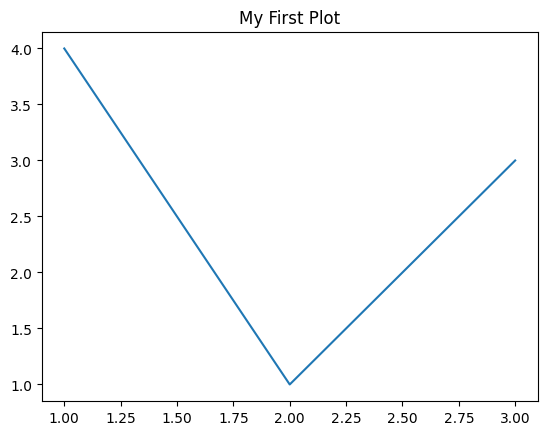

In [1]:
import matplotlib.pyplot as plt
import numpy as np

# 最简单的绘图：一个 Figure，一个 Axes
fig, ax = plt.subplots()          # 返回 Figure 和单个 Axes
ax.plot([1, 2, 3], [4, 1, 3])    # 折线
ax.set_title("My First Plot")
plt.show()

## 2. Figure 与 Axes：`plt.subplots`

`plt.subplots(nrows, ncols, figsize=(width, height))` 一次性创建多个子图。

| 调用方式 | 返回的 axes |
|---------|------------|
| `plt.subplots()` | 单个 `Axes` 对象 |
| `plt.subplots(1, 2)` | 形状 `(2,)` 的数组 |
| `plt.subplots(2, 5)` | 形状 `(2, 5)` 的数组，`axes.flat` 可线性遍历 |

`figsize` 单位为英寸，`dpi=150` 表示每英寸 150 像素。

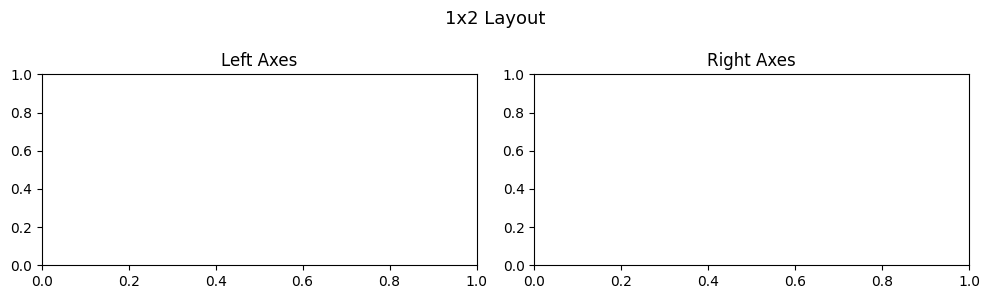

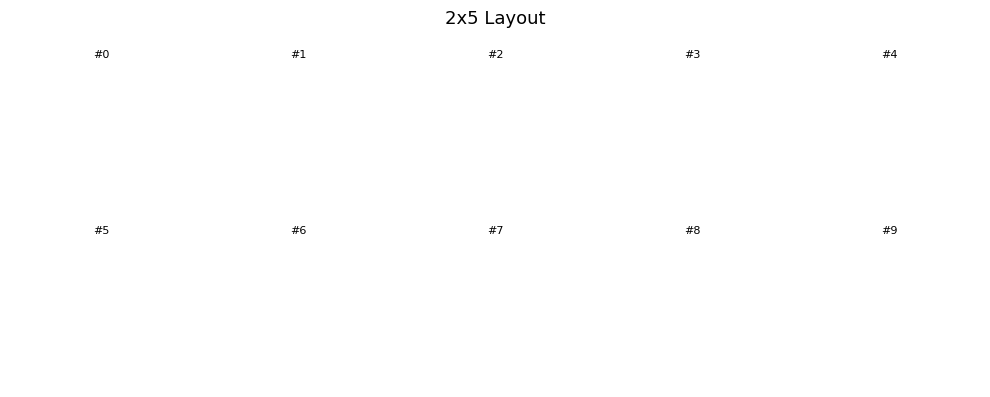

In [2]:
rng = np.random.default_rng(42)

# ── 1×2 子图（训练曲线场景）
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3))
ax1.set_title("Left Axes")
ax2.set_title("Right Axes")
fig.suptitle("1x2 Layout", fontsize=13)   # 整张图的总标题
plt.tight_layout()
plt.show()

# ── 2×5 子图（模板图像场景），用 axes.flat 线性遍历
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for i, ax in enumerate(axes.flat):        # axes.flat 将 (2,5) 展平为长度 10 的迭代器
    ax.set_title(f"#{i}", fontsize=8)
    ax.axis("off")                         # 隐藏坐标轴刻度与边框
fig.suptitle("2x5 Layout", fontsize=13)
plt.tight_layout()
plt.show()

## 3. 折线图：`ax.plot`

训练曲线（loss / accuracy 随 step 变化）是最典型的折线图场景。

常用参数：`color`、`linewidth`、`label`（配合 `ax.legend()` 显示）。

`ax.axvline(x=..., linestyle='--', ...)` 在指定 x 坐标处绘制垂直虚线，常用于标记 epoch 分界。

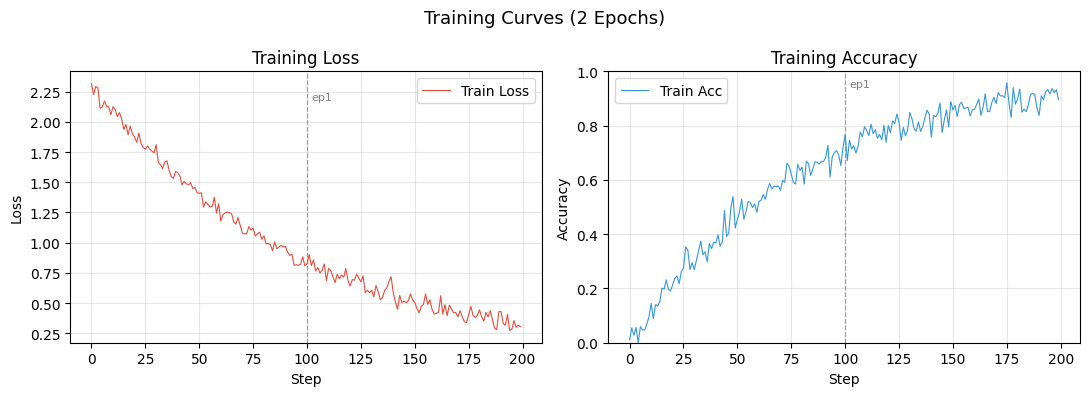

In [3]:
rng = np.random.default_rng(42)

# 模拟两个 epoch 共 200 步的训练数据
steps  = np.arange(200)
losses = 2.3 * np.exp(-steps / 100) + 0.05 * rng.standard_normal(200)
accs   = 1 - np.exp(-steps / 80)   + 0.03 * rng.standard_normal(200)
accs   = np.clip(accs, 0, 1)

epoch_boundaries = [100]   # 第 1 个 epoch 结束的 step

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

# ── 左图：Loss 曲线
ax1.plot(steps, losses, color="#e74c3c", linewidth=0.8, label="Train Loss")
for b in epoch_boundaries:
    ax1.axvline(x=b, color="gray", linestyle="--", linewidth=0.9, alpha=0.7)
    ax1.text(b + 2, losses.max() * 0.97, "ep1", fontsize=8, color="gray", va="top")
ax1.set_xlabel("Step")
ax1.set_ylabel("Loss")
ax1.set_title("Training Loss")
ax1.legend()
ax1.grid(True, alpha=0.3)

# ── 右图：Accuracy 曲线
ax2.plot(steps, accs, color="#3498db", linewidth=0.8, label="Train Acc")
for b in epoch_boundaries:
    ax2.axvline(x=b, color="gray", linestyle="--", linewidth=0.9, alpha=0.7)
    ax2.text(b + 2, 0.97, "ep1", fontsize=8, color="gray", va="top")
ax2.set_xlabel("Step")
ax2.set_ylabel("Accuracy")
ax2.set_title("Training Accuracy")
ax2.set_ylim(0, 1)       # 固定 y 轴范围，确保可读性
ax2.legend()
ax2.grid(True, alpha=0.3)

fig.suptitle("Training Curves (2 Epochs)", fontsize=13)
plt.tight_layout()
plt.show()

## 4. 柱状图：`ax.bar`

柱状图适合比较若干类别/方法的指标（如各方法的运行时间对比）。

- `ax.bar(x_labels, heights, color=list, width=0.5)` — `color` 可传列表逐柱着色
- `ax.text(x, y, s, ha='center', va='bottom')` — 在柱子顶端标注数值（如准确率）
- `ax.grid(axis='y', alpha=0.3)` — 只显示横向网格线，减少视觉噪声

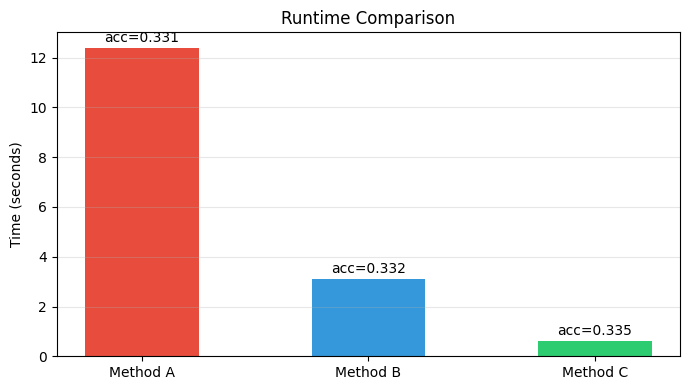

In [4]:
# 模拟三种方法的运行时间与对应准确率
names  = ["Method A", "Method B", "Method C"]
times  = [12.4, 3.1, 0.6]          # 秒
accs   = [0.331, 0.332, 0.335]     # 准确率（近似相等）
colors = ["#e74c3c", "#3498db", "#2ecc71"]

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(names, times, color=colors, width=0.5)

# 在每根柱子顶端标注准确率
for bar, acc in zip(bars, accs):
    ax.text(
        bar.get_x() + bar.get_width() / 2,   # 柱子中心 x
        bar.get_height() + max(times) * 0.01, # 柱顶稍上方
        f"acc={acc:.3f}",
        ha="center", va="bottom", fontsize=10
    )

ax.set_ylabel("Time (seconds)")
ax.set_title("Runtime Comparison")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## 5. 图像显示：`ax.imshow`

`ax.imshow(img)` 将 NumPy 数组渲染为图像：

| 数组形状 | 含义 |
|---------|------|
| `(H, W)` | 灰度图，值域 0–255 或 0–1 |
| `(H, W, 3)` | RGB 彩色图，值域 `float [0,1]` 或 `uint8 [0,255]` |

**关键细节**：
- Matplotlib 的 `imshow` 期望通道维度在**最后**，即 `(H, W, C)`，而模型权重矩阵通常存储为 `(C, H, W)`，需要用 `np.transpose(img, (1, 2, 0))` 转换
- `ax.axis("off")` 隐藏坐标轴，让图像更整洁

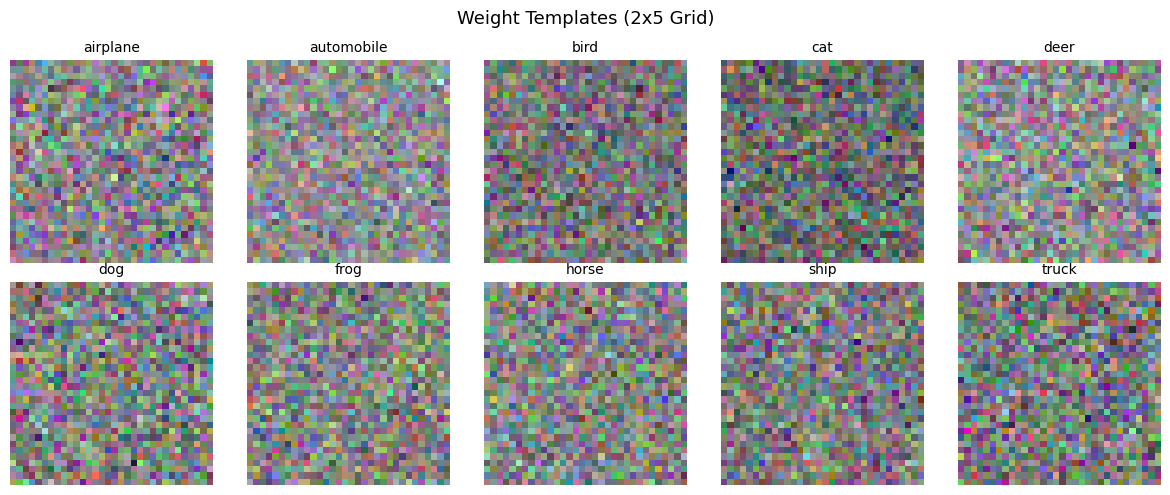

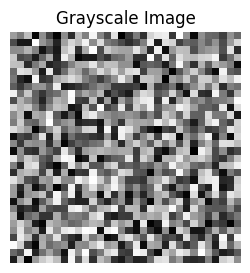

In [5]:
rng = np.random.default_rng(42)

# 模拟 10 个类别的权重向量，形状 (10, 3, 32, 32)
CLASSES = ["airplane", "automobile", "bird", "cat", "deer",
           "dog", "frog", "horse", "ship", "truck"]
W = rng.standard_normal((10, 3, 32, 32)).astype(np.float32)

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
fig.suptitle("Weight Templates (2x5 Grid)", fontsize=13)

for idx, ax in enumerate(axes.flat):
    t = W[idx]                                           # 取第 idx 个类别，形状 (3,32,32)
    t = (t - t.min()) / (t.max() - t.min() + 1e-8)     # min-max 归一化到 [0,1]
    img = np.transpose(t, (1, 2, 0))                    # (C,H,W) → (H,W,C)，imshow 需要此顺序
    ax.imshow(img)
    ax.set_title(CLASSES[idx], fontsize=10)
    ax.axis("off")                                       # 隐藏坐标轴

plt.tight_layout()
plt.show()

# ── 灰度图示例（单通道）
gray = rng.integers(0, 256, size=(32, 32), dtype=np.uint8)
fig, ax = plt.subplots(figsize=(3, 3))
ax.imshow(gray, cmap="gray", vmin=0, vmax=255)
ax.set_title("Grayscale Image")
ax.axis("off")
plt.show()

## 6. 装饰与标注

| 方法 | 作用 |
|------|------|
| `ax.set_xlabel(s)` / `ax.set_ylabel(s)` | 坐标轴标签 |
| `ax.set_title(s)` | 子图标题 |
| `fig.suptitle(s, fontsize=13)` | 整张图的总标题 |
| `ax.legend()` | 显示图例（需要 `plot(..., label=...)` 先设置标签） |
| `ax.grid(True, alpha=0.3)` | 显示网格，`axis='y'` 只显示横向 |
| `ax.set_ylim(lo, hi)` | 固定 y 轴范围 |
| `ax.axis("off")` | 隐藏所有坐标轴元素（图像子图常用） |
| `ax.text(x, y, s, ha, va, fontsize, color)` | 在数据坐标 `(x, y)` 处放置文字 |
| `ax.axvline(x, color, linestyle, linewidth, alpha)` | 绘制垂直参考线 |
| `plt.tight_layout()` | 自动调整子图间距，防止标签重叠 |

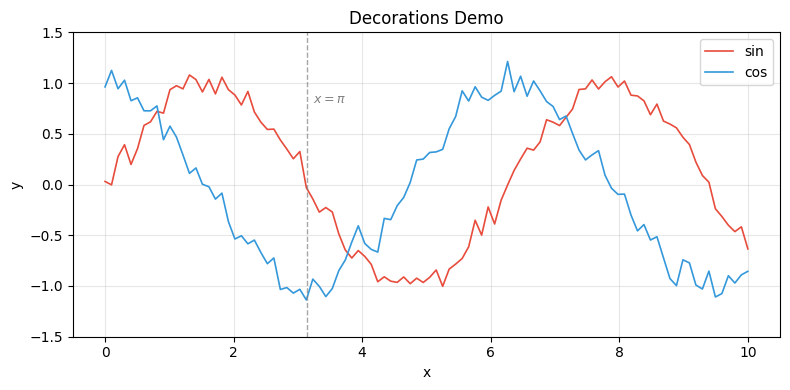

In [6]:
rng = np.random.default_rng(42)
x = np.linspace(0, 10, 100)
y1 = np.sin(x) + 0.1 * rng.standard_normal(100)
y2 = np.cos(x) + 0.1 * rng.standard_normal(100)

fig, ax = plt.subplots(figsize=(8, 4))

ax.plot(x, y1, color="#e74c3c", linewidth=1.2, label="sin")
ax.plot(x, y2, color="#3498db", linewidth=1.2, label="cos")

# 垂直参考线（例如标记某个关键 step）
ax.axvline(x=np.pi, color="gray", linestyle="--", linewidth=1.0, alpha=0.7)
ax.text(np.pi + 0.1, 0.9, r"$x=\pi$", fontsize=9, color="gray", va="top")

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Decorations Demo")
ax.set_ylim(-1.5, 1.5)
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 7. 保存与关闭

实验脚本通常不显示窗口，而是直接把图保存到文件，再关闭释放内存。

```python
fig.savefig(path, dpi=150, bbox_inches="tight")
plt.close(fig)
```

- `dpi=150`：输出分辨率，150 dpi 在报告中清晰且文件不过大
- `bbox_inches="tight"`：自动裁剪留白，保证标题/标签不被截断
- `plt.close(fig)`：**必须**关闭，否则在循环中会造成内存泄漏

In [7]:
import os, tempfile

rng  = np.random.default_rng(42)
data = rng.random((50,))

fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(data, color="#2ecc71", linewidth=1)
ax.set_title("Saved Figure")
plt.tight_layout()

# 保存到临时路径演示（实际实验中替换为 args.save 指定的路径）
save_path = os.path.join(tempfile.gettempdir(), "demo.png")
fig.savefig(save_path, dpi=150, bbox_inches="tight")
plt.close(fig)   # 关闭，释放内存

print(f"已保存 -> {save_path}")

# 验证保存成功
from PIL import Image
img = np.array(Image.open(save_path))
print("图像像素尺寸:", img.shape)   # (H, W, RGBA 或 RGB)

已保存 -> /var/folders/6j/_3d0_q391w7c3rk2g2r1y7_00000gn/T/demo.png
图像像素尺寸: (432, 885, 4)
